# 2.5 bổ sung: trước/sau tiền xử lý trên CHÍNH nhóm ảnh có vấn đề

**Câu hỏi.** Trên toàn tập, macro-F1 của `median3`, `clahe_L_c2_t8` và kết hợp `median3+clahe_L_c2_t8` không khác biệt rõ so với baseline
(`outputs/preprocess/comparison_*.csv`). Nhưng phương pháp được chọn để xử lý một *vấn đề cụ thể*, nên có thể hiệu ứng chỉ xuất hiện trên ảnh
mang vấn đề đó và bị "pha loãng" trong toàn tập. Notebook này kiểm tra điều đó.

**Thiết kế (đặt trước khi xem số, không đổi theo kết quả):**
- Nhóm = cờ EDA có sẵn (`outputs/eda/image_flags.csv`): `F_noise` (σ nhiễu > rào Tukey, loại ảnh nhiều lông) và `F_low_contrast`
  (mức xám da − tổn thương < 20, mask Otsu thô). **Không tạo nhóm/ngưỡng mới.**
- Cặp so sánh: nhóm nhiễu × {baseline, `median3`, kết hợp}; nhóm tương phản thấp × {baseline, `clahe_L_c2_t8`, kết hợp}.
- **Đối chứng** = phần ảnh còn lại của cùng split, cùng cấu hình. Nếu nhóm cải thiện nhưng phần còn lại cũng cải thiện bằng ấy thì đó không
  phải hiệu ứng riêng → báo cáo thêm hiệu Δ(nhóm) − Δ(còn lại) (difference-in-differences, DiD).
- Không train lại: chỉ đọc dự đoán ngoài mẫu của 3 seed (42, 43, 44) trên val/test. **Test là kết quả chính**; val (đã dùng chọn epoch) chỉ để kiểm tra
  tính nhất quán.
- **Quy tắc kết luận** (giống `compare.py`, áp dụng cho nhóm con): "cải thiện rõ" chỉ khi Δ > 0, CI95 bootstrap cụm `lesion_id` không chứa 0,
  3/3 seed cùng dấu, **và** |Δ| > std giữa seed của baseline trên chính nhóm đó. "Riêng cho nhóm" cần thêm CI95 của DiD không chứa 0.
  Đối xứng cho "tệ hơn rõ"; ngược lại "không khác biệt rõ".

Code: `src/preprocess/subgroup.py`. Bảng: `outputs/preprocess/subgroup/`. Hình: `outputs/figures/preprocess/subgroup/`.

In [1]:
import os, sys
from pathlib import Path
if not Path("archive").exists() and Path("../archive").exists():
    os.chdir("..")
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.preprocess import subgroup as SG
from src.eda.plots import CLASSES, setup_style

setup_style()
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
OUT = SG.OUT; OUT.mkdir(parents=True, exist_ok=True)
N_BOOT = 1000

flags = pd.read_csv("outputs/eda/image_flags.csv")
meta = pd.read_csv("archive/HAM10000_metadata.csv")
paths = pd.concat([pd.read_csv(f"outputs/splits/{s}.csv") for s in ("val", "test")]).set_index("image_id")["path"].to_dict()
R = {sp: SG.load_all(sp) for sp in ("test", "val")}          # dự đoán + xác suất, ghép theo image_id
M = {sp: SG.membership(R[sp]["baseline"]["ids"], flags) for sp in R}
for sp in R:
    print(sp, "n ảnh =", len(R[sp]["baseline"]["ids"]), {g: int(m.sum()) for g, m in M[sp].items()})

test n ảnh = 2004 {'noise': 139, 'low_contrast': 89}
val n ảnh = 1603 {'noise': 132, 'low_contrast': 71}


## A. Cỡ mẫu và thành phần lớp của từng nhóm

Cần biết trước nhóm gồm những lớp nào, vì chỉ số trên nhóm con phụ thuộc mạnh vào thành phần lớp (một nhóm toàn `nv` dễ có accuracy cao).
`frac_follow_up` = tỉ lệ ảnh có `dx_type = follow_up` (chỉ có ở lớp `nv`): EDA cho thấy σ nhiễu gắn với nguồn ảnh nhiều hơn lớp bệnh.

In [2]:
COMP = SG.composition(R, flags, meta)
COMP.to_csv(OUT / "composition.csv", index=False)
display(COMP.round(3))

,group,part,split,n_images,n_lesions,n_akiec,n_bcc,n_bkl,n_df,n_mel,n_nv,n_vasc,frac_histo,frac_follow_up,frac_consensus,frac_confocal
0,noise,group,test,139,139,0,0,8,5,5,120,1,0.079,0.835,0.079,0.007
1,noise,rest,test,1865,1364,66,103,212,18,217,1221,28,0.557,0.343,0.092,0.008
2,low_contrast,group,test,89,79,8,19,22,2,5,33,0,0.652,0.180,0.124,0.045
3,low_contrast,rest,test,1915,1449,58,84,198,21,217,1308,29,0.518,0.386,0.090,0.006
4,noise,group,val,132,132,0,0,11,4,2,113,2,0.053,0.811,0.136,0.000
5,noise,rest,val,1471,1068,52,82,165,15,176,960,21,0.581,0.329,0.082,0.009
6,low_contrast,group,val,71,61,10,10,20,4,1,26,0,0.535,0.141,0.254,0.070
7,low_contrast,rest,val,1532,1166,42,72,156,15,177,1047,23,0.537,0.379,0.078,0.005


## B. Chỉ số trên nhóm con: accuracy, macro-F1, balanced accuracy, recall/precision từng lớp

- Tính riêng cho từng seed rồi lấy mean ± std (ddof = 1) qua 3 seed; Δ = phương pháp − baseline **ghép cặp theo seed**.
- **Chỉ tính các lớp có ảnh thật trong nhóm** (lớp vắng không đóng góp F1 = 0 giả). Dự đoán rơi vào lớp vắng vẫn làm giảm recall của lớp thật.
- **Cảnh báo:** macro-F1 / balanced accuracy trên nhóm con **rất không ổn định** khi có lớp chỉ vài ảnh: nhóm nhiễu trên test có `vasc` = 1 ảnh,
  `df` = 5, `mel` = 5, `bkl` = 8; nhóm tương phản thấp có `df` = 2, `mel` = 5, `akiec` = 8 (bảng A). Một ảnh `vasc` đổi đúng/sai làm recall lớp đó
  nhảy 0 ↔ 1 và kéo macro-F1 của nhóm đi ~1/5. Vì vậy **accuracy** và phân tích từng ảnh (mục D–E) là bằng chứng chính; macro-F1 nhóm con chỉ tham khảo.
- CI95: bootstrap 1000 lần, rút lại `lesion_id` của **toàn split** (có hoàn lại) rồi lọc ra nhóm/còn lại, nên Δ nhóm, Δ còn lại và DiD tính trên cùng mẫu.

In [3]:
PS = pd.concat([SG.per_seed_metrics(R[sp], M[sp], sp) for sp in R], ignore_index=True)
PS.to_csv(OUT / "metrics_per_seed.csv", index=False)
BOOT = {sp: SG.boot_deltas(R[sp], M[sp], n_boot=N_BOOT) for sp in R}
SUM = pd.concat([SG.summary_table(PS, BOOT[sp], sp) for sp in ("test", "val")], ignore_index=True)
SUM.to_csv(OUT / "metrics_summary.csv", index=False)

cols = ["group", "part", "config", "metric", "n_images", "mean", "std", "delta_mean", "delta_sign", "ci_lo", "ci_hi",
        "baseline_seed_std", "did_mean", "did_lo", "did_hi", "verdict"]
for sp in ("test", "val"):
    print(f"===== {sp.upper()} (accuracy, macro-F1, balanced acc) =====")
    display(SUM[(SUM.split == sp) & SUM.metric.isin(SG.METRICS3)][cols].round(3))

===== TEST (accuracy, macro-F1, balanced acc) =====


,group,part,config,metric,n_images,mean,std,delta_mean,delta_sign,ci_lo,ci_hi,baseline_seed_std,did_mean,did_lo,did_hi,verdict
0,noise,group,baseline,accuracy,139,0.921,0.012,NaN,NaN,NaN,NaN,0.012,NaN,NaN,NaN,NaN
1,noise,group,baseline,macro_f1,139,0.657,0.068,NaN,NaN,NaN,NaN,0.068,NaN,NaN,NaN,NaN
2,noise,group,baseline,balanced_acc,139,0.687,0.007,NaN,NaN,NaN,NaN,0.007,NaN,NaN,NaN,NaN
18,noise,group,median3,accuracy,139,0.909,0.011,-0.012,0+/3-,-0.037,0.015,0.012,-0.022,-0.049,0.006,không khác biệt rõ
19,noise,group,median3,macro_f1,139,0.526,0.132,-0.131,1+/2-,-0.217,-0.003,0.068,-0.142,-0.235,-0.010,không khác biệt rõ
20,noise,group,median3,balanced_acc,139,0.503,0.146,-0.184,0+/3-,-0.263,0.010,0.007,-0.171,-0.249,0.027,không khác biệt rõ
36,noise,group,median3+clahe_L_c2_t8,accuracy,139,0.914,0.012,-0.007,2+/1-,-0.029,0.016,0.012,-0.019,-0.044,0.007,không khác biệt rõ
37,noise,group,median3+clahe_L_c2_t8,macro_f1,139,0.588,0.065,-0.069,2+/1-,-0.174,0.012,0.068,-0.067,-0.175,0.022,không khác biệt rõ
38,noise,group,median3+clahe_L_c2_t8,balanced_acc,139,0.629,0.045,-0.058,0+/3-,-0.151,0.010,0.007,-0.047,-0.148,0.033,không khác biệt rõ
54,noise,rest,baseline,accuracy,1865,0.802,0.025,NaN,NaN,NaN,NaN,0.025,NaN,NaN,NaN,NaN


===== VAL (accuracy, macro-F1, balanced acc) =====


,group,part,config,metric,n_images,mean,std,delta_mean,delta_sign,ci_lo,ci_hi,baseline_seed_std,did_mean,did_lo,did_hi,verdict
261,noise,group,baseline,accuracy,132,0.934,0.039,NaN,NaN,NaN,NaN,0.039,NaN,NaN,NaN,NaN
262,noise,group,baseline,macro_f1,132,0.727,0.100,NaN,NaN,NaN,NaN,0.100,NaN,NaN,NaN,NaN
263,noise,group,baseline,balanced_acc,132,0.800,0.073,NaN,NaN,NaN,NaN,0.073,NaN,NaN,NaN,NaN
279,noise,group,median3,accuracy,132,0.962,0.015,0.028,2+/1-,-0.003,0.058,0.039,0.013,-0.021,0.048,không khác biệt rõ
280,noise,group,median3,macro_f1,132,0.815,0.130,0.088,2+/1-,-0.058,0.183,0.100,0.078,-0.072,0.176,không khác biệt rõ
281,noise,group,median3,balanced_acc,132,0.806,0.086,0.007,2+/1-,-0.154,0.136,0.073,0.007,-0.150,0.147,không khác biệt rõ
297,noise,group,median3+clahe_L_c2_t8,accuracy,132,0.952,0.004,0.018,2+/1-,-0.003,0.039,0.039,0.000,-0.025,0.026,không khác biệt rõ
298,noise,group,median3+clahe_L_c2_t8,macro_f1,132,0.788,0.082,0.061,2+/1-,-0.081,0.177,0.100,0.063,-0.085,0.180,không khác biệt rõ
299,noise,group,median3+clahe_L_c2_t8,balanced_acc,132,0.837,0.141,0.037,2+/1-,-0.138,0.187,0.073,0.055,-0.122,0.211,không khác biệt rõ
315,noise,rest,baseline,accuracy,1471,0.801,0.026,NaN,NaN,NaN,NaN,0.026,NaN,NaN,NaN,NaN


In [4]:
# Recall / precision từng lớp trên nhóm (test): mean ± std 3 seed, Δ ghép cặp; kèm n ảnh của lớp để thấy lớp nào chỉ vài ảnh
rows = []
for g, sp in SG.GROUPS.items():
    comp = COMP[(COMP.group == g) & (COMP.part == "group") & (COMP.split == "test")].iloc[0]
    for c in CLASSES:
        if comp[f"n_{c}"] == 0:
            continue
        for kind in ("recall", "precision"):
            rec = {"group": g, "class": c, "n_class": int(comp[f"n_{c}"]), "metric": kind}
            for cfg in ["baseline"] + sp["methods"]:
                s = SUM[(SUM.split == "test") & (SUM.group == g) & (SUM.part == "group") & (SUM.config == cfg) & (SUM.metric == f"{kind}_{c}")].iloc[0]
                rec[cfg] = f"{s['mean']:.2f} ± {s['std']:.2f}" + ("" if cfg == "baseline" else f" (Δ {s.delta_mean:+.2f}, {s.delta_sign})")
            rows.append(rec)
PC = pd.DataFrame(rows); PC.to_csv(OUT / "per_class_group_test.csv", index=False)
display(PC)

,group,class,n_class,metric,baseline,median3,median3+clahe_L_c2_t8,clahe_L_c2_t8
0,noise,bkl,8,recall,0.79 ± 0.14,"0.67 ± 0.14 (Δ -0.12, 1+/2-)","0.83 ± 0.14 (Δ +0.04, 2+/1-)",NaN
1,noise,bkl,8,precision,0.67 ± 0.04,"0.64 ± 0.04 (Δ -0.03, 0+/3-)","0.64 ± 0.10 (Δ -0.03, 1+/2-)",NaN
2,noise,df,5,recall,0.53 ± 0.12,"0.47 ± 0.23 (Δ -0.07, 1+/1-)","0.27 ± 0.12 (Δ -0.27, 0+/3-)",NaN
3,noise,df,5,precision,1.00 ± 0.00,"0.83 ± 0.29 (Δ -0.17, 0+/1-)","0.72 ± 0.25 (Δ -0.28, 0+/2-)",NaN
4,noise,mel,5,recall,0.13 ± 0.12,"0.07 ± 0.12 (Δ -0.07, 1+/2-)","0.07 ± 0.12 (Δ -0.07, 1+/2-)",NaN
5,noise,mel,5,precision,0.40 ± 0.53,"0.17 ± 0.29 (Δ -0.23, 1+/2-)","0.33 ± 0.58 (Δ -0.07, 1+/2-)",NaN
6,noise,nv,120,recall,0.98 ± 0.01,"0.98 ± 0.01 (Δ +0.01, 1+/1-)","0.98 ± 0.01 (Δ +0.00, 2+/1-)",NaN
7,noise,nv,120,precision,0.96 ± 0.01,"0.93 ± 0.01 (Δ -0.02, 0+/3-)","0.95 ± 0.02 (Δ -0.01, 1+/2-)",NaN
8,noise,vasc,1,recall,1.00 ± 0.00,"0.33 ± 0.58 (Δ -0.67, 0+/2-)","1.00 ± 0.00 (Δ +0.00, 0+/0-)",NaN
9,noise,vasc,1,precision,0.61 ± 0.35,"0.33 ± 0.58 (Δ -0.28, 1+/2-)","0.67 ± 0.29 (Δ +0.06, 2+/1-)",NaN


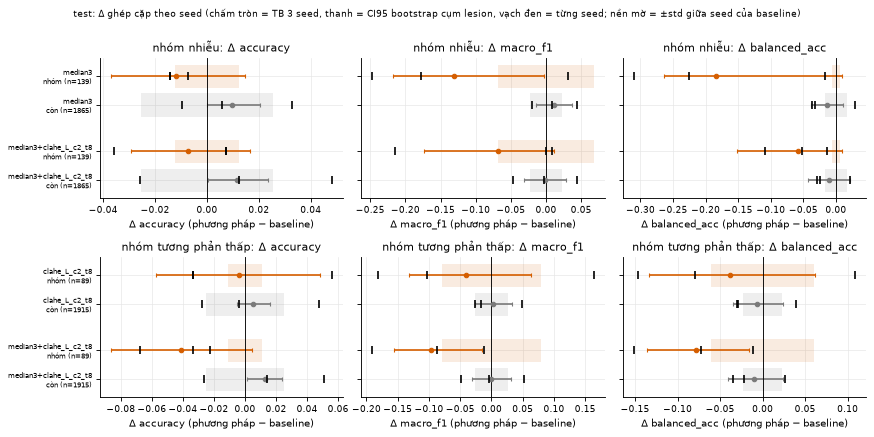

In [5]:
F_ = SG.fig_deltas(SUM, "test"); plt.show()
F_ = SG.fig_deltas(SUM, "val"); plt.close("all")

**Hình S1.** Δ (phương pháp − baseline) của accuracy, macro-F1 và balanced accuracy trên **test**, ghép cặp theo seed, cho nhóm nhiễu (hàng trên;
n = 139 ảnh nhóm, 1865 ảnh còn lại) và nhóm tương phản thấp (hàng dưới; n = 89 / 1915). Chấm tròn = trung bình 3 seed (42/43/44), thanh = CI95
bootstrap cụm `lesion_id` (1000 lần), vạch đen = Δ của từng seed; cam = nhóm, xám = phần còn lại (đối chứng); nền mờ = ±1 std giữa seed của baseline.
Macro-F1/balanced acc của nhóm chỉ tính các lớp có trong nhóm và dao động mạnh do lớp ít ảnh. Bản val: `fig_s1_subgroup_delta_val`.

## C. Confusion matrix của nhóm con

Số đếm **cộng qua 3 seed** (mỗi ảnh xuất hiện 3 lần) để ma trận đủ dày, kèm tỉ lệ theo hàng (= recall/nhầm lẫn theo lớp thật). Cột thứ ba là ma trận
hiệu (phương pháp − baseline): ô đường chéo dương = nhiều ảnh được đoán đúng hơn; ô ngoài chéo dương = nhầm sang lớp đó nhiều hơn.
Thứ tự lớp và màu nhãn theo `CLASSES`/`CLASS_COLORS` của EDA.

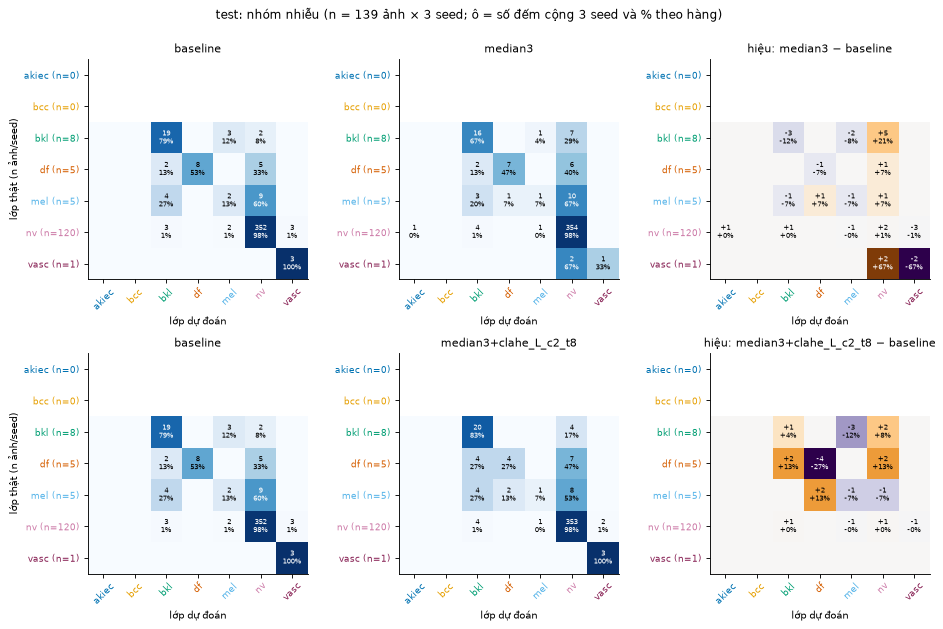

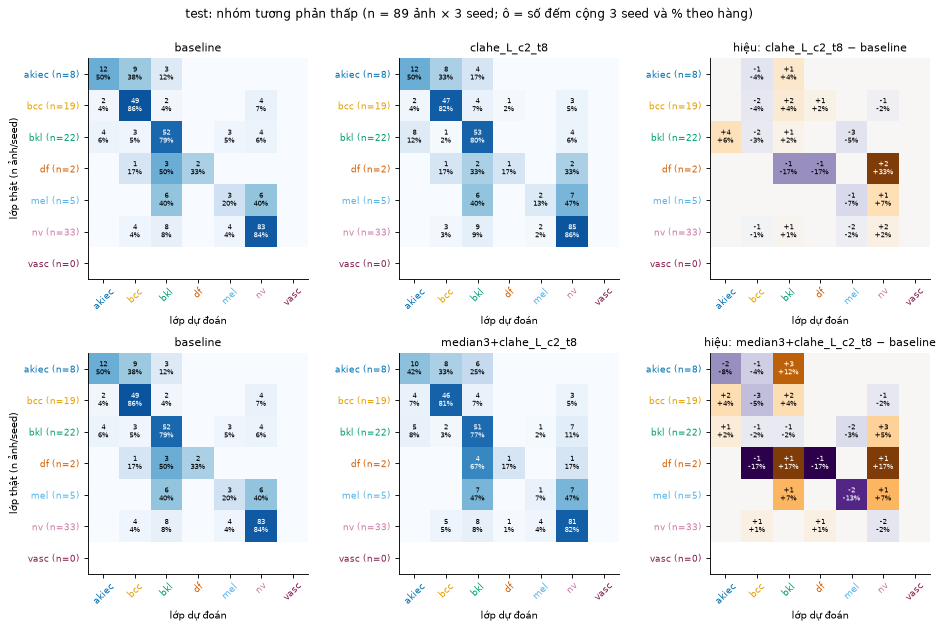

config              baseline  clahe_L_c2_t8  median3  median3+clahe_L_c2_t8
group        true                                                          
low_contrast akiec      12.0           12.0      NaN                   10.0
             bcc        49.0           47.0      NaN                   46.0
             bkl        52.0           53.0      NaN                   51.0
             df          2.0            1.0      NaN                    1.0
             mel         3.0            2.0      NaN                    1.0
             nv         83.0           85.0      NaN                   81.0
             vasc        0.0            0.0      NaN                    0.0
noise        akiec       0.0            NaN      0.0                    0.0
             bcc         0.0            NaN      0.0                    0.0
             bkl        19.0            NaN     16.0                   20.0
             df          8.0            NaN      7.0                    4.0
             mel         2.0            NaN      1.0                    1.0
             nv        352.0            NaN    354.0                  353.0
             vasc        3.0            NaN      1.0                    3.0

In [6]:
CL = pd.concat([SG.confusion_long(R[sp], M[sp], sp) for sp in R], ignore_index=True)
CL.to_csv(OUT / "confusion_counts.csv", index=False)
for g in SG.GROUPS:
    F_ = SG.fig_confusion(CL, g, "test"); plt.show()
    F_ = SG.fig_confusion(CL, g, "val"); plt.close("all")
# Tóm tắt: đường chéo (số lần đúng, cộng 3 seed) theo lớp
diag = CL[(CL.true == CL.pred)].pivot_table(index=["split", "group", "true"], columns="config", values="count_sum_3seeds", aggfunc="sum")
display(diag.loc["test"])

**Hình S2.** Confusion matrix trên test của nhóm nhiễu (`fig_s2_cm_noise_test`, n = 139 ảnh × 3 seed) và nhóm tương phản thấp
(`fig_s2_cm_low_contrast_test`, n = 89 ảnh × 3 seed). Mỗi hàng: baseline | phương pháp | hiệu. Ô = số đếm cộng 3 seed và % theo hàng (mẫu số = số lần
xuất hiện của lớp thật trong 3 seed); hàng lớp vắng để trống. Nhãn trục ghi n ảnh/seed của từng lớp. Bản val: `*_val`.

## D. So sánh từng ảnh: chuyển trạng thái đúng/sai trước → sau

Chỉ số tổng hợp có thể giữ nguyên dù nhiều ảnh đổi trạng thái theo hai chiều ngược nhau. Vì vậy với **từng ảnh, cùng seed**, so đúng/sai của baseline
và phương pháp: CC (đúng→đúng), **WC (sai→đúng, được sửa)**, **CW (đúng→sai, bị làm hỏng)**, WW (sai→sai). Kiểm định **McNemar exact** (binomial trên
WC vs CW) cho từng seed và cho đa số phiếu 3 seed; `net_fixed` = WC − CW.

**Mức dao động ngẫu nhiên:** cùng bảng đó nhưng so baseline seed a với baseline seed b (42→43, 43→44, 44→42). Nếu số ảnh "đổi trạng thái" khi thêm
tiền xử lý không lớn hơn số ảnh đổi trạng thái chỉ vì đổi seed, thì phần lớn thay đổi là dao động huấn luyện, không phải tác động của phương pháp.

p-value hiệu chỉnh Holm trong họ kiểm định McNemar từng seed của mỗi split (2 nhóm × 2 phần × 2 phương pháp × 3 seed = 24 kiểm định).

In [7]:
TR = pd.concat([SG.transitions(R[sp], M[sp], sp) for sp in R], ignore_index=True)
TR["mcnemar_p_holm"] = np.nan
for sp in R:
    fam = (TR.split == sp) & TR["compare"].str.startswith("seed") & ~TR.config.str.startswith("baseline")
    TR.loc[fam, "mcnemar_p_holm"] = SG.holm(TR.loc[fam, "mcnemar_p"])
TR.to_csv(OUT / "transitions.csv", index=False)
cols = ["group", "part", "config", "compare", "n", "CC", "WC", "CW", "WW", "net_fixed", "flip_rate", "mcnemar_p", "mcnemar_p_holm"]
display(TR[(TR.split == "test") & (TR.part == "group")][cols].round(4))

,group,part,config,compare,n,CC,WC,CW,WW,net_fixed,flip_rate,mcnemar_p,mcnemar_p_holm
0,noise,group,median3,seed42,139,127,1,3,8,-2,0.0288,0.6250,1.0
1,noise,group,median3,seed43,139,122,4,5,8,-1,0.0647,1.0000,1.0
2,noise,group,median3,seed44,139,121,4,6,8,-2,0.0719,0.7539,1.0
3,noise,group,median3,đa số 3 seed,139,125,3,3,8,0,0.0432,1.0000,NaN
4,noise,group,median3+clahe_L_c2_t8,seed42,139,124,1,6,8,-5,0.0504,0.1250,1.0
5,noise,group,median3+clahe_L_c2_t8,seed43,139,123,5,4,7,1,0.0647,1.0000,1.0
6,noise,group,median3+clahe_L_c2_t8,seed44,139,123,5,4,7,1,0.0647,1.0000,1.0
7,noise,group,median3+clahe_L_c2_t8,đa số 3 seed,139,124,2,4,9,-2,0.0432,0.6875,NaN
8,noise,group,baseline (cặp seed),seed42→seed43,139,124,3,6,6,-3,0.0647,0.5078,NaN
9,noise,group,baseline (cặp seed),seed43→seed44,139,124,3,3,9,0,0.0432,1.0000,NaN


In [8]:
# Đối chứng (phần còn lại) – đa số phiếu và cặp seed, để so tỉ lệ đổi trạng thái; val để kiểm tra nhất quán
display(TR[(TR.split == "test") & (TR.part == "rest") & ((TR["compare"] == "đa số 3 seed") | TR.config.str.startswith("baseline"))][cols].round(4))
print("VAL – nhóm, đa số 3 seed:")
display(TR[(TR.split == "val") & (TR.part == "group") & (TR["compare"] == "đa số 3 seed")][cols].round(4))

,group,part,config,compare,n,CC,WC,CW,WW,net_fixed,flip_rate,mcnemar_p,mcnemar_p_holm
14,noise,rest,median3,đa số 3 seed,1865,1444,101,89,231,12,0.1019,0.4249,NaN
18,noise,rest,median3+clahe_L_c2_t8,đa số 3 seed,1865,1448,103,85,229,18,0.1008,0.2149,NaN
19,noise,rest,baseline (cặp seed),seed42→seed43,1865,1309,133,221,202,-88,0.1898,0.0000,NaN
20,noise,rest,baseline (cặp seed),seed43→seed44,1865,1312,204,130,219,74,0.1791,0.0001,NaN
21,noise,rest,baseline (cặp seed),seed44→seed42,1865,1396,134,120,215,14,0.1362,0.4147,NaN
36,low_contrast,rest,clahe_L_c2_t8,đa số 3 seed,1915,1493,97,99,226,-2,0.1023,0.9431,NaN
40,low_contrast,rest,median3+clahe_L_c2_t8,đa số 3 seed,1915,1510,101,82,222,19,0.0956,0.1832,NaN
41,low_contrast,rest,baseline (cặp seed),seed42→seed43,1915,1375,127,217,196,-90,0.1796,0.0000,NaN
42,low_contrast,rest,baseline (cặp seed),seed43→seed44,1915,1379,198,123,215,75,0.1676,0.0000,NaN
43,low_contrast,rest,baseline (cặp seed),seed44→seed42,1915,1464,128,113,210,15,0.1258,0.3672,NaN


VAL – nhóm, đa số 3 seed:


,group,part,config,compare,n,CC,WC,CW,WW,net_fixed,flip_rate,mcnemar_p,mcnemar_p_holm
47,noise,group,median3,đa số 3 seed,132,123,6,2,1,4,0.0606,0.2891,NaN
51,noise,group,median3+clahe_L_c2_t8,đa số 3 seed,132,124,5,1,2,4,0.0455,0.2188,NaN
69,low_contrast,group,clahe_L_c2_t8,đa số 3 seed,71,48,5,3,15,2,0.1127,0.7266,NaN
73,low_contrast,group,median3+clahe_L_c2_t8,đa số 3 seed,71,48,10,3,10,7,0.1831,0.0923,NaN


**Nhất quán vs dao động.** `fix_3of3` = ảnh sai ở **cả 3** seed baseline và đúng ở **cả 3** seed phương pháp (thay đổi không thể do một seed may mắn);
`break_3of3` ngược lại. `baseline_unstable` = số ảnh baseline đúng ở 1–2/3 seed (bản thân baseline đã dao động). `baseline_seedpair_flip_rate` = tỉ lệ ảnh
đổi đúng/sai giữa hai seed baseline (TB 3 cặp), so với `method_vs_baseline_flip_rate` (cùng seed).

In [9]:
CO = pd.concat([SG.consistency(R[sp], M[sp], sp) for sp in R], ignore_index=True)
CO.to_csv(OUT / "consistency.csv", index=False)
display(CO.round(4))

,group,part,split,config,n,baseline_unstable,method_unstable,baseline_seedpair_flip_rate,method_vs_baseline_flip_rate,fix_3of3,break_3of3,fix_ge2,break_ge2,fix_any,break_any,net_3of3
0,noise,group,test,median3,139,10,11,0.0480,0.0552,0,1,2,2,7,11,-1
1,noise,group,test,median3+clahe_L_c2_t8,139,10,11,0.0480,0.0600,0,0,2,3,9,11,0
2,noise,rest,test,median3,1865,471,421,0.1684,0.1408,3,2,57,41,361,324,1
3,noise,rest,test,median3+clahe_L_c2_t8,1865,471,412,0.1684,0.1467,4,6,69,44,370,328,-2
4,low_contrast,group,test,clahe_L_c2_t8,89,28,24,0.2097,0.1985,1,0,4,6,21,21,1
5,low_contrast,group,test,median3+clahe_L_c2_t8,89,28,28,0.2097,0.1610,0,0,3,1,13,26,0
6,low_contrast,rest,test,clahe_L_c2_t8,1915,453,430,0.1577,0.1384,5,6,52,51,356,325,-1
7,low_contrast,rest,test,median3+clahe_L_c2_t8,1915,453,395,0.1577,0.1398,4,6,68,46,366,313,-2
8,noise,group,val,median3,132,15,8,0.0758,0.0833,0,1,6,2,16,8,-1
9,noise,group,val,median3+clahe_L_c2_t8,132,15,14,0.0758,0.0682,0,0,3,1,14,9,0


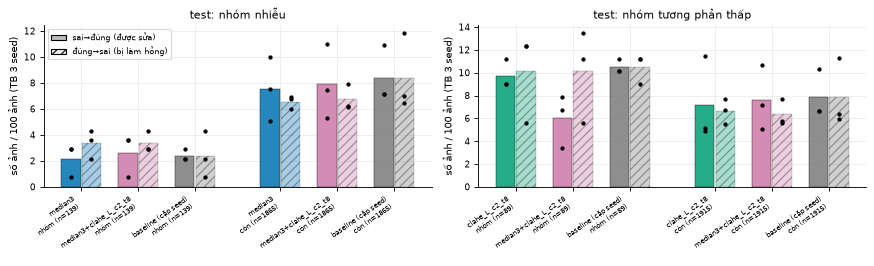

In [10]:
F_ = SG.fig_transitions(TR, "test"); plt.show()
F_ = SG.fig_transitions(TR, "val"); plt.close("all")

**Hình S3.** Số ảnh sai→đúng (cột đặc) và đúng→sai (cột gạch) trên mỗi 100 ảnh của test, trung bình 3 seed (chấm = từng seed), cho nhóm và phần còn lại.
Cột xám "baseline (cặp seed)" = cùng phép đếm khi chỉ đổi seed của baseline (42→43, 43→44, 44→42): mức dao động ngẫu nhiên (vì 3 cặp tạo vòng kín nên TB sai→đúng = TB đúng→sai theo cấu tạo; chỉ chiều cao cột là thông tin). n ghi dưới trục.
Bản val: `fig_s3_transitions_val`.

## E. Xác suất của lớp đúng trước và sau (Δ prob_true)

Đúng/sai là thông tin thô (ảnh p = 0.49 → 0.51 cũng là "được sửa"). Δ prob_true = p_sau(lớp đúng) − p_trước(lớp đúng), cùng seed, rồi lấy trung bình 3 seed
cho mỗi ảnh. Kiểm định **Wilcoxon ghép cặp** (H0: trung vị Δ = 0) ở **mức lesion** (TB các ảnh cùng `lesion_id`, vì ảnh cùng lesion không độc lập) và ở
mức ảnh (tham khảo). So nhóm với phần còn lại bằng Mann–Whitney + **Cliff's δ** (δ > 0: nhóm được tăng xác suất nhiều hơn phần còn lại).
Mức dao động: `median_abs_seedpair_baseline` = trung vị |Δ p| giữa hai seed của chính baseline.

,group,split,config,part,n_images,n_lesions,median_dprob,mean_dprob,frac_pos,median_abs_dprob,median_abs_seedpair_baseline,wilcoxon_p_lesion,wilcoxon_p_image,cliffs_delta_group_vs_rest,mwu_p_group_vs_rest
0,noise,test,median3,group,139,139,0.0045,0.0107,0.7986,0.0152,0.0245,0.0000,0.0000,0.1068,0.0378
1,noise,test,median3,rest,1865,1364,0.0019,0.0081,0.6118,0.0378,0.0782,0.0000,0.0000,NaN,NaN
2,noise,test,median3+clahe_L_c2_t8,group,139,139,0.0040,0.0097,0.7770,0.0134,0.0245,0.0000,0.0000,0.0321,0.5327
3,noise,test,median3+clahe_L_c2_t8,rest,1865,1364,0.0030,0.0176,0.6445,0.0350,0.0782,0.0000,0.0000,NaN,NaN
4,low_contrast,test,clahe_L_c2_t8,group,89,79,0.0042,0.0153,0.5843,0.0589,0.1251,0.1111,0.1359,-0.0300,0.6526
5,low_contrast,test,clahe_L_c2_t8,rest,1915,1449,0.0036,0.0183,0.6950,0.0331,0.0693,0.0000,0.0000,NaN,NaN
6,low_contrast,test,median3+clahe_L_c2_t8,group,89,79,-0.0002,-0.0201,0.4831,0.0387,0.1251,0.2823,0.2159,-0.2175,0.0011
7,low_contrast,test,median3+clahe_L_c2_t8,rest,1915,1449,0.0033,0.0188,0.6616,0.0320,0.0693,0.0000,0.0000,NaN,NaN
8,noise,val,median3,group,132,132,0.0069,0.0311,0.8409,0.0125,0.0215,0.0000,0.0000,0.1486,0.0053
9,noise,val,median3,rest,1471,1068,0.0027,0.0135,0.6438,0.0384,0.0883,0.0000,0.0000,NaN,NaN


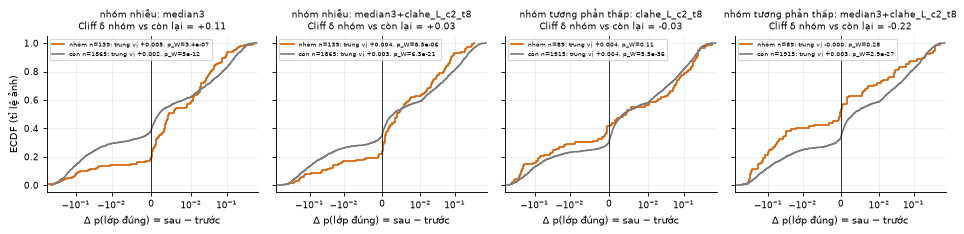

In [11]:
DP = pd.concat([SG.dprob_per_image(R[sp], M[sp], sp) for sp in R], ignore_index=True)
DP.to_csv(OUT / "dprob_per_image.csv", index=False)
DT = SG.dprob_tests(DP)
DT.to_csv(OUT / "dprob_tests.csv", index=False)
display(DT.round(4))
F_ = SG.fig_dprob(DP, DT, "test"); plt.show()
F_ = SG.fig_dprob(DP, DT, "val"); plt.close("all")

**Hình S4.** ECDF của Δ p(lớp đúng) theo ảnh trên test (trung bình 3 seed; trục x symlog, tuyến tính trong ±0.01), nhóm (cam) vs phần còn lại (xám),
cho từng cặp nhóm × phương pháp. Chú thích: n ảnh, trung vị Δ, p Wilcoxon mức lesion; tiêu đề: Cliff's δ nhóm vs còn lại (mức lesion).
Đường lệch sang phải = phương pháp làm tăng xác suất lớp đúng. Bản val: `fig_s4_dprob_ecdf_val`.

## F. "100 ảnh" của nhóm lỗi, chọn có hệ thống

Mỗi nhóm lấy **100 ảnh ngẫu nhiên (seed 42) từ test**; nhóm tương phản thấp trên test chỉ có 89 ảnh → lấy hết 89 ảnh test và **bổ sung 11 ảnh
ngẫu nhiên (seed 42) từ val** của cùng nhóm (cột `split` ghi rõ). Danh sách + dự đoán/xác suất từng seed lưu ở `sample100_<nhóm>.csv`.
Bảng chuyển trạng thái tính trên đúng 100 ảnh này (từng seed, đa số phiếu, nhất quán 3/3, và cặp seed của baseline).

In [12]:
S100 = SG.sample100(flags, R["test"], R["val"])
SD = SG.sample_detail(S100, R, paths)
for g in SG.GROUPS:
    SD[SD.group == g].to_csv(OUT / f"sample100_{g}.csv", index=False)
print(S100.groupby(["group", "split"]).size())
print(SD.groupby("group").dx.value_counts().unstack(fill_value=0)[[c for c in CLASSES if c in SD.dx.unique()]])
ST = SG.sample_transitions(SD)
ST.to_csv(OUT / "sample100_transitions.csv", index=False)
display(ST.round(4))

group         split
low_contrast  test      89
              val       11
noise         test     100
dtype: int64
dx            akiec  bcc  bkl  df  mel  nv  vasc
group                                           
low_contrast      8   22   24   2    5  39     0
noise             0    0    5   4    5  85     1


,group,config,compare,CC,WC,CW,WW,n_split,net_fixed,mcnemar_p
0,noise,median3,seed42,90.0,1,3,6.0,100,-2,0.6250
1,noise,median3,seed43,90.0,2,2,6.0,100,0,1.0000
2,noise,median3,seed44,87.0,3,4,6.0,100,-1,1.0000
3,noise,median3,đa số 3 seed,89.0,2,3,6.0,100,-1,1.0000
4,noise,median3,nhất quán 3/3,NaN,0,1,NaN,100,-1,NaN
5,noise,median3+clahe_L_c2_t8,seed42,87.0,1,6,6.0,100,-5,0.1250
6,noise,median3+clahe_L_c2_t8,seed43,88.0,3,4,5.0,100,-1,1.0000
7,noise,median3+clahe_L_c2_t8,seed44,88.0,4,3,5.0,100,1,1.0000
8,noise,median3+clahe_L_c2_t8,đa số 3 seed,88.0,1,4,7.0,100,-3,0.3750
9,noise,median3+clahe_L_c2_t8,nhất quán 3/3,NaN,0,0,NaN,100,0,NaN


**Lưới minh họa – quy tắc chọn (cố định trước):** trong 100 ảnh của mỗi nhóm, với mỗi phương pháp, lấy ảnh **sai→đúng nhất quán** (sai ở cả 3 seed
baseline, đúng ở cả 3 seed phương pháp) và ảnh **đúng→sai nhất quán**; số ảnh hiện mỗi phía k = min(6, #sửa, #hỏng), chọn ngẫu nhiên seed 42, để hình
không thiên về phía "đẹp". Nếu một phía có 0 ảnh thì hiện tối đa 3 ảnh của phía còn lại và tiêu đề hình ghi rõ số lượng mỗi phía.
Mỗi ảnh: trước | sau xử lý (hàm `get_preprocess` của `src/preprocess`, ở 600×450) | |sau − trước| × 4 (vì `median3` gần như không thấy bằng mắt).

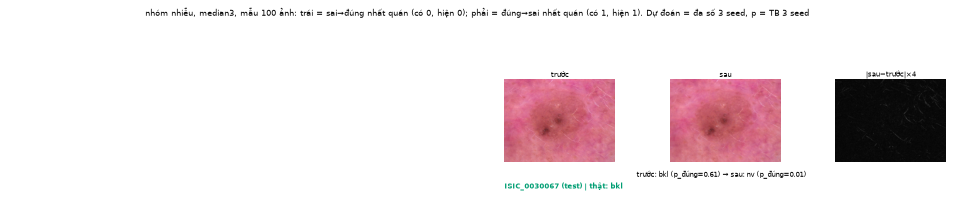

noise × median3+clahe_L_c2_t8: không có ảnh đổi trạng thái nhất quán 3/3 nào trong 100 ảnh → không vẽ lưới


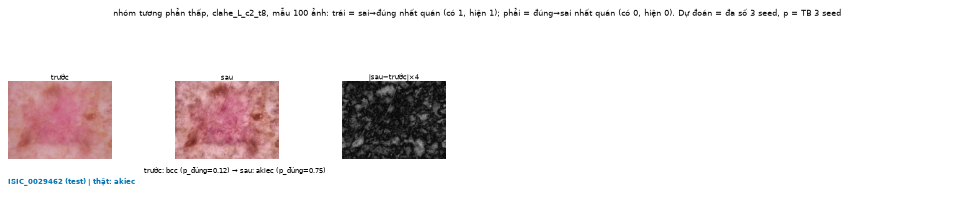

low_contrast × median3+clahe_L_c2_t8: không có ảnh đổi trạng thái nhất quán 3/3 nào trong 100 ảnh → không vẽ lưới


,group,config,n_fix3,n_break3,shown_fix,shown_break,shown_ids
0,noise,median3,0,1,0,1,ISIC_0030067
1,noise,median3+clahe_L_c2_t8,0,0,0,0,
2,low_contrast,clahe_L_c2_t8,1,0,1,0,ISIC_0029462
3,low_contrast,median3+clahe_L_c2_t8,0,0,0,0,


In [13]:
GRID = []
for g, sp in SG.GROUPS.items():
    for mth in sp["methods"]:
        fig, info = SG.grid_examples(SD, g, mth)
        GRID.append(info)
        if fig is None:
            print(f"{g} × {mth}: không có ảnh đổi trạng thái nhất quán 3/3 nào trong 100 ảnh → không vẽ lưới")
        else:
            plt.show()
GRID = pd.DataFrame(GRID); GRID.to_csv(OUT / "grid_selection.csv", index=False)
display(GRID)

**Hình S5.** Ví dụ trong mẫu 100 ảnh: trái = sai→đúng nhất quán qua 3 seed, phải = đúng→sai nhất quán; số ảnh mỗi phía bằng nhau theo quy tắc trên
(số có/hiện ghi ở tiêu đề). Mỗi ô ghi `image_id`, split, lớp thật (màu lớp), dự đoán đa số 3 seed và p(lớp đúng) TB 3 seed trước → sau.
File: `grid_s5_<nhóm>_<phương pháp>.png` (300 dpi). Đây là minh họa định tính, không phải bằng chứng hiệu quả.

## G. Bảng số chính để trích dẫn

In [14]:
key = []
for sp in ("test", "val"):
    for g, gsp in SG.GROUPS.items():
        for mth in gsp["methods"]:
            rec = {"split": sp, "group": g, "config": mth}
            for part in ("group", "rest"):
                s = SUM[(SUM.split == sp) & (SUM.group == g) & (SUM.part == part) & (SUM.config == mth) & (SUM.metric == "accuracy")].iloc[0]
                rec[f"n_{part}"] = s.n_images
                rec[f"Δacc_{part}"] = f"{s.delta_mean:+.3f} [{s.ci_lo:+.3f}; {s.ci_hi:+.3f}] {s.delta_sign}"
                if part == "group":
                    rec["DiD_acc"] = f"{s.did_mean:+.3f} [{s.did_lo:+.3f}; {s.did_hi:+.3f}]"
                    rec["verdict_acc"] = s.verdict
                    f = SUM[(SUM.split == sp) & (SUM.group == g) & (SUM.part == part) & (SUM.config == mth) & (SUM.metric == "macro_f1")].iloc[0]
                    rec["ΔF1_group"] = f"{f.delta_mean:+.3f} [{f.ci_lo:+.3f}; {f.ci_hi:+.3f}] {f.delta_sign}"
                    rec["verdict_F1"] = f.verdict
            t = TR[(TR.split == sp) & (TR.group == g) & (TR.part == "group") & (TR.config == mth)]
            rec["WC/CW seed42,43,44"] = "; ".join(f"{r.WC}/{r.CW}" for r in t[t["compare"].str.startswith("seed")].itertuples())
            rec["McNemar p (từng seed)"] = ", ".join(f"{p:.2g}" for p in t[t["compare"].str.startswith("seed")].mcnemar_p)
            c = CO[(CO.split == sp) & (CO.group == g) & (CO.part == "group") & (CO.config == mth)].iloc[0]
            rec["fix3/break3"] = f"{c.fix_3of3}/{c.break_3of3}"
            rec["flip phương pháp vs cặp seed baseline"] = f"{c.method_vs_baseline_flip_rate:.3f} vs {c.baseline_seedpair_flip_rate:.3f}"
            d = DT[(DT.split == sp) & (DT.group == g) & (DT.config == mth) & (DT.part == "group")].iloc[0]
            rec["Δp_true trung vị (p_W lesion)"] = f"{d.median_dprob:+.4f} ({d.wilcoxon_p_lesion:.2g})"
            rec["Cliff δ nhóm vs còn lại"] = round(d.cliffs_delta_group_vs_rest, 3)
            key.append(rec)
KEY = pd.DataFrame(key); KEY.to_csv(OUT / "key_numbers.csv", index=False)
display(KEY.T)

,0,1,2,3,4,5,6,7
split,test,test,test,test,val,val,val,val
group,noise,noise,low_contrast,low_contrast,noise,noise,low_contrast,low_contrast
config,median3,median3+clahe_L_c2_t8,clahe_L_c2_t8,median3+clahe_L_c2_t8,median3,median3+clahe_L_c2_t8,clahe_L_c2_t8,median3+clahe_L_c2_t8
n_group,139,139,89,89,132,132,71,71
Δacc_group,-0.012 [-0.037; +0.015] 0+/3-,-0.007 [-0.029; +0.016] 2+/1-,-0.004 [-0.057; +0.048] 1+/2-,-0.041 [-0.086; +0.004] 0+/3-,+0.028 [-0.003; +0.058] 2+/1-,+0.018 [-0.003; +0.039] 2+/1-,+0.014 [-0.051; +0.074] 1+/2-,+0.056 [-0.021; +0.132] 2+/0-
DiD_acc,-0.022 [-0.049; +0.006],-0.019 [-0.044; +0.007],-0.009 [-0.063; +0.045],-0.054 [-0.102; -0.008],+0.013 [-0.021; +0.048],+0.000 [-0.025; +0.026],-0.001 [-0.066; +0.059],+0.041 [-0.036; +0.119]
verdict_acc,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ
ΔF1_group,-0.131 [-0.217; -0.003] 1+/2-,-0.069 [-0.174; +0.012] 2+/1-,-0.040 [-0.132; +0.063] 1+/2-,-0.097 [-0.156; -0.015] 0+/3-,+0.088 [-0.058; +0.183] 2+/1-,+0.061 [-0.081; +0.177] 2+/1-,-0.010 [-0.076; +0.055] 1+/2-,+0.040 [-0.063; +0.128] 2+/1-
verdict_F1,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,tệ hơn rõ; riêng cho nhóm,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ,không khác biệt rõ
n_rest,1865,1865,1915,1915,1471,1471,1532,1532


## H. Kết luận

*(Mọi số trích từ `outputs/preprocess/subgroup/{metrics_summary,transitions,consistency,dprob_tests,sample100_transitions,key_numbers}.csv`; Δ = phương pháp − baseline,
ghép cặp theo seed, TB 3 seed 42/43/44; CI95 = bootstrap cụm `lesion_id` 1000 lần; quy tắc kết luận đặt ở đầu notebook.)*

**Bảng tóm tắt (test, nhóm vấn đề).**

| Nhóm (n test) | Phương pháp | Δ accuracy [CI95], dấu 3 seed | DiD accuracy (nhóm − còn lại) | WC/CW từng seed (McNemar p) | sửa/hỏng nhất quán 3/3 | Kết luận |
|---|---|---|---|---|---|---|
| nhiễu (139) | `median3` | −0.012 [−0.037; +0.015], 0+/3− | −0.022 [−0.049; +0.006] | 1/3, 4/5, 4/6 (0.62; 1; 0.75) | 0/1 | không khác biệt rõ |
| nhiễu (139) | kết hợp | −0.007 [−0.029; +0.016], 2+/1− | −0.019 [−0.044; +0.007] | 1/6, 5/4, 5/4 (0.12; 1; 1) | 0/0 | không khác biệt rõ |
| tương phản thấp (89) | `clahe_L_c2_t8` | −0.004 [−0.057; +0.048], 1+/2− | −0.009 [−0.063; +0.045] | 10/5, 8/11, 8/11 (0.30; 0.65; 0.65) | 1/0 | không khác biệt rõ |
| tương phản thấp (89) | kết hợp | −0.041 [−0.086; +0.004], 0+/3− | −0.054 [−0.102; −0.008] | 3/5, 6/12, 7/10 (0.73; 0.24; 0.63) | 0/0 | tín hiệu xấu đi trên test, không lặp lại trên val (xem dưới) |

(WC = sai→đúng, CW = đúng→sai, cùng seed. Mức dao động do đổi seed của chính baseline: nhóm nhiễu 4.8% ảnh đổi trạng thái, nhóm tương phản thấp 21.0%.)

**Nhóm nhiễu (`F_noise`).**
- Quan sát: không cấu hình nào cải thiện accuracy hay macro-F1 trên nhóm. Δ accuracy của `median3` âm ở cả 3 seed nhưng CI chứa 0 và |Δ| = 0.012 chỉ
  bằng std giữa seed của baseline trên nhóm (0.012). Macro-F1 nhóm giảm −0.131 (CI [−0.217; −0.003], 1+/2−), nhưng phần lớn do **1 ảnh `vasc`**
  (recall `vasc` 1.00 → 0.33 với `median3`); dấu không nhất quán nên không đạt quy tắc và không nên diễn giải.
- Tỉ lệ ảnh đổi trạng thái khi áp dụng `median3` (5.5%/seed) gần bằng tỉ lệ đổi chỉ vì đổi seed baseline (4.8%); 0 ảnh được sửa và 1 ảnh bị làm hỏng
  nhất quán qua 3 seed. Trên mẫu 100 ảnh: đa số phiếu 2 sửa / 3 hỏng (McNemar p = 1.0).
- Δ p(lớp đúng) dương nhỏ nhưng có hệ thống: trung vị +0.0045, 80% ảnh tăng (Wilcoxon mức lesion p = 3.4e−7), hơi lớn hơn phần còn lại (Cliff δ = +0.11).
  Diễn giải thận trọng: `median3` có thể làm CNN *tự tin hơn một chút* trên ảnh nhiễu, nhưng độ lớn (trung vị |Δp| = 0.015) nhỏ hơn mức dao động giữa hai
  seed baseline (0.025) và hầu như không đổi quyết định — vì 86% nhóm là `nv` (83% `follow_up`) và baseline đã đúng 92% ảnh của nhóm.
- Val: Δ accuracy `median3` +0.028 [−0.003; +0.058], 2+/1− — ngược dấu với test, CI chứa 0 → không nhất quán, củng cố kết luận "không khác biệt rõ".

**Nhóm tương phản thấp (`F_low_contrast`).**
- `clahe_L_c2_t8`: không khác biệt rõ trên mọi chỉ số (Δ accuracy −0.004, CI [−0.057; +0.048]). Tỉ lệ ảnh đổi trạng thái 19.9%/seed **không lớn hơn**
  mức đổi do seed của baseline (21.0%); 1 sửa / 0 hỏng nhất quán; Δ p(lớp đúng) trung vị +0.004 (Wilcoxon p = 0.11), Cliff δ so với phần còn lại = −0.03.
  Confusion matrix (Hình S2) chỉ đổi ±1–4 lần đếm mỗi ô (cộng 3 seed). Mẫu 100 ảnh: đa số phiếu 6 sửa / 8 hỏng (p = 0.79).
- Kết hợp `median3+clahe_L_c2_t8`: trên test, accuracy giảm ở cả 3 seed (−0.041, CI [−0.086; +0.004]); macro-F1 nhóm −0.097 [−0.156; −0.015] (0+/3−,
  |Δ| > std seed baseline 0.078 → theo quy tắc là "tệ hơn rõ", DiD [−0.159; −0.018]); DiD accuracy −0.054 [−0.102; −0.008]; Δ p(lớp đúng) của nhóm thấp hơn
  phần còn lại (Cliff δ = −0.22, Mann–Whitney p = 0.001). Ma trận hiệu cho thấy nhầm `akiec→bkl` (+3) và `bkl→nv` (+3) tăng.
  **Nhưng** McNemar từng seed không có ý nghĩa (p = 0.73; 0.24; 0.63), không có ảnh nào hỏng nhất quán 3/3, và trên **val chiều ngược lại**
  (Δ accuracy +0.056 [−0.021; +0.132], macro-F1 +0.040). Vì vậy chỉ ghi nhận *tín hiệu xấu đi trên test, chưa lặp lại trên val*;
  không kết luận chắc chắn kết hợp gây hại cho nhóm này.

**Đối chứng (phần còn lại).** Phần ảnh không thuộc nhóm có Δ accuracy dương nhỏ với mọi phương pháp (test +0.005 đến +0.013; val +0.015 đến +0.017, CI val
không chứa 0). Tức là nếu có cải thiện nhỏ thì nó **không tập trung vào nhóm ảnh lỗi** mà phương pháp được thiết kế để xử lý: DiD accuracy trên test âm
hoặc ≈ 0 ở cả 4 cặp.

**Trả lời câu hỏi.** Khi xét riêng tập ảnh bị nhiễu hoặc tương phản thấp, **không có bằng chứng** `median3` hay `clahe_L_c2_t8` sửa được lỗi của CNN:
Δ trên nhóm nằm trong mức dao động giữa seed, số ảnh được sửa ≈ số ảnh bị làm hỏng, và gần như không có ảnh nào được sửa nhất quán qua 3 seed.
Đây là kết quả âm và được báo cáo đúng như vậy; nó phù hợp với EDA (σ nhiễu nhỏ; nhóm nhiễu chủ yếu là ảnh `nv` vốn đã được đoán đúng).

**Hạn chế.**
- Mask Otsu dùng để định nghĩa `F_low_contrast` sai ở khoảng 40% ảnh trong mẫu đã kiểm tra (`outputs/preprocess/lowcontrast_mask_audit.csv`; đánh giá bằng mắt
  bởi AI, cần người kiểm lại) → nhóm "tương phản thấp" lẫn nhiều ảnh không thực sự tương phản thấp, có thể làm loãng hiệu ứng nếu có.
- Nhóm nhiễu gần như chỉ là `nv` (test 120/139) và 83% `dx_type = follow_up` (bảng A): kết quả không khái quát cho ảnh nhiễu của các lớp khác,
  và σ nhiễu gắn với nguồn ảnh (EDA), có thể là đặc trưng thiết bị hơn là "lỗi".
- Cỡ mẫu nhỏ: test 139 / 89 ảnh; các lớp `vasc` (1), `df` (2–5), `mel` (5) → macro-F1 và recall theo lớp trên nhóm con dao động mạnh; CI accuracy nhóm tương
  phản thấp rộng ≈ 0.10, nên chỉ phát hiện được hiệu ứng lớn.
- Chỉ 3 seed; huấn luyện dùng AMP + cudnn.benchmark nên không tất định từng bit (đã nằm trong dao động seed).
- Không tạo thêm nhóm con hay ngưỡng mới; mọi phân tích ở đây theo thiết kế đặt ở đầu notebook (không có phân tích thăm dò bổ sung).